# 02 · Transcription & Speaker Segmentation
**Assessment task 4.** For each call:
1. **Whisper** (`turbo`) transcribes the audio with word-level timestamps.
2. **pyannote** diarization finds *who spoke when* (2 speakers).
3. Each word is assigned to the speaker whose segment overlaps it most → **speaker turns** (Speaker 1 / Speaker 2).
4. **Role labelling** decides which speaker is the *Agent* and which is the *Customer*:
   an LLM (Groq, Llama 3) reads the opening turns and names the agent; a keyword heuristic
   ("thank you for calling", "how can I help" vs. "I have a problem") is the fallback and a cross-check.
5. Turns with low Whisper word confidence are flagged as **possibly unclear audio**.
6. Results are validated against the human ground truth: **WER**, **role accuracy**, **DER**.

**Before running:** Runtime → Change runtime type → **T4 GPU**. Add `HF_TOKEN` and `GROQ_API_KEY` in Colab Secrets (🔑),
and accept the terms on [pyannote/speaker-diarization-community-1](https://huggingface.co/pyannote/speaker-diarization-community-1)
(and, for the fallback, [speaker-diarization-3.1](https://huggingface.co/pyannote/speaker-diarization-3.1) + [segmentation-3.0](https://huggingface.co/pyannote/segmentation-3.0)).

In [1]:
# ---- Setup: open the project folder (run this cell first) ----
import os, sys
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")                       # results are saved to Drive, so they survive restarts
    PROJECT_DIR = "/content/drive/MyDrive/call-center-ai"  # <- change if your folder is elsewhere
else:
    PROJECT_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(PROJECT_DIR)
sys.path.insert(0, PROJECT_DIR)
print("Working in:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in: /content/drive/MyDrive/call-center-ai


In [ ]:
!pip install -q openai-whisper pyannote.audio jiwer groq soundfile
import os; os.kill(os.getpid(), 9)   # restarts the session automatically after installing

In [3]:
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None (this will be slow)")

GPU: Tesla T4


## 1. Load the models

In [4]:
from src import config
from src.data_loader import load_sample_metadata
from src.transcriber import WhisperTranscriber
from src.diarizer import SpeakerDiarizer
from src.llm import GroqLLM
from src.role_labeler import RoleLabeler
from src.pipeline import CallCenterPipeline

config.ensure_dirs()
llm = GroqLLM()
pipe = CallCenterPipeline(
    transcriber=WhisperTranscriber(),                                  # OpenAI Whisper turbo
    diarizer=SpeakerDiarizer(hf_token=config.get_secret("HF_TOKEN")),  # pyannote
    role_labeler=RoleLabeler(llm=llm),                                 # LLM + keyword fallback
)
print("Diarization model:", pipe.diarizer.model_name)

Groq model: openai/gpt-oss-120b (fallbacks: ['openai/gpt-oss-20b', 'qwen/qwen3.8-27b'])
Diarization model: pyannote/speaker-diarization-community-1


## 2. Process every call (skips calls already done, so it is safe to re-run)

In [5]:
import json
for p in sorted(config.TRANSCRIPTS_DIR.glob("call_*.json")):
    try:
        json.load(open(p))
    except Exception:
        print("corrupted -> deleted:", p.name)
        p.unlink()

In [6]:
import time
records = load_sample_metadata()
for r in records:
    out = config.TRANSCRIPTS_DIR / f"{r['call_id']}.json"
    if out.exists():
        continue
    t0 = time.time()
    rec = pipe.transcribe_and_segment(r["call_id"], config.PROJECT_ROOT / r["audio_path"])
    print(f"{r['call_id']}: {len(rec['turns'])} turns, roles by {rec['role_method']}, {time.time() - t0:.0f}s")

## 3. Look at one segmented transcript

In [7]:
from src.pipeline import load_transcripts
rec = load_transcripts()[0]
print("Speakers:", rec["speaker_roles"], "| method:", rec["role_method"])
print("Why:", rec["role_reason"], "\n")
for t in rec["turns"][:15]:
    flag = "  ⚠ unclear" if t["low_confidence"] else ""
    print(f"[{t['start']:6.1f}s] {t['speaker_label']} ({t['role']}): {t['text']}{flag}")

Speakers: {'Speaker 1': 'Agent', 'Speaker 2': 'Customer'} | method: llm
Why: LLM (confidence 0.99): Speaker_01 greets, introduces themselves as a representative and handles the inquiry, while Speaker_00 asks about a missing package. 

[  13.0s] Speaker 1 (Agent): Good morning. Thank you for calling Fox Korea. My name is Ali. How can I help you today?
[  20.4s] Speaker 2 (Customer): Hi, my name is Jenny. I'm waiting for a really important package, but it hasn't has not arrived on time and I was told it would arrive by yesterday still not here I really need this package oh
[  34.2s] Speaker 1 (Agent): I'm sorry to hear dad I understand you're calling about a package that hasn't arrived on time especially since it contains important information let's get this sorted out for you and you wanted this urgently can i please have your tracking number so i can look up the shipment details
[  56.8s] Speaker 2 (Customer): yeah it's four five nine two one seven eight four five
[  63.2s] Speaker 1 (

## 4. Validation against the human ground truth

In [8]:
import pandas as pd
from src.evaluator import word_error_rate, role_accuracy, diarization_error_rate, reference_text

gt = {r["call_id"]: r for r in load_sample_metadata()}
rows = []
for rec in load_transcripts():
    segs = gt[rec["call_id"]]["segments"]
    hyp = " ".join(t["text"] for t in rec["turns"])
    w = word_error_rate(reference_text(segs), hyp) or {}
    rows.append({"call_id": rec["call_id"], "accent": gt[rec["call_id"]]["accent"], **w,
                 "role_accuracy": role_accuracy(rec["turns"], segs),
                 "der": diarization_error_rate(rec["turns"], segs),
                 "role_method": rec["role_method"],
                 "low_conf_turns": sum(t["low_confidence"] for t in rec["turns"])})
ev = pd.DataFrame(rows)
ev.to_csv(config.EVALUATION_FILE, index=False)

total_err = (ev["substitutions"] + ev["deletions"] + ev["insertions"]).sum()
print(f"Corpus WER (basic normalization): {total_err / ev['ref_words'].sum():.1%}")
if "wer_whisper_norm" in ev:
    print(f"Corpus WER (Whisper normalizer):  {ev['errors_whisper_norm'].sum() / ev['ref_words_whisper_norm'].sum():.1%}")
print(f"Mean role accuracy: {ev['role_accuracy'].mean():.1%}")
print(f"Mean DER: {ev['der'].mean():.1%}" if ev["der"].notna().any() else "DER not available")
ev.sort_values("wer", ascending=False)

/usr/local/lib/python3.13/dist-packages/pyannote/metrics/utils.py:199: UserWarning: 'uem' was approximated by the union of 'reference' and 'hypothesis' extents.
  warnings.warn(


Corpus WER (basic normalization): 15.9%
Corpus WER (Whisper normalizer):  13.3%
Mean role accuracy: 93.7%
Mean DER: 18.7%


,call_id,accent,wer,substitutions,deletions,insertions,ref_words,wer_whisper_norm,errors_whisper_norm,ref_words_whisper_norm,role_accuracy,der,role_method,low_conf_turns
8,call_009,en-MX,0.2351,39,111,8,672,0.2190,145,662,0.9544,0.3406,llm,1
3,call_004,en-GB,0.2159,77,153,53,1311,0.2019,281,1392,0.7786,0.2505,llm,1
17,call_018,en-GB,0.2060,109,118,19,1194,0.1844,229,1242,0.7980,0.2699,llm,0
4,call_005,en-GB_SCT,0.1916,49,87,38,908,0.1893,181,956,0.8898,0.2062,llm,2
5,call_006,en-GB_WLS,0.1900,72,72,8,800,0.1632,134,821,0.9508,0.3020,llm,4
6,call_007,en-IE,0.1849,78,112,25,1163,0.1661,198,1192,0.9132,0.1707,llm,1
13,call_014,en-ZA,0.1725,29,42,18,516,0.1014,50,493,0.9946,0.1067,llm,0
19,call_020,en-GB_WLS,0.1717,70,32,17,693,0.1464,107,731,0.9743,0.2418,llm,1
18,call_019,en-GB_SCT,0.1597,81,106,11,1240,0.1199,152,1268,0.9254,0.2124,llm,0
2,call_003,en-CN,0.1591,48,25,22,597,0.1413,88,623,0.9890,0.1285,llm,2


In [9]:
print(ev[["call_id","accent","wer","role_accuracy","der","low_conf_turns"]].round(3).to_csv(index=False))

call_id,accent,wer,role_accuracy,der,low_conf_turns
call_001,en-AU,0.118,0.976,0.137,1
call_002,en-CA,0.138,0.865,0.252,3
call_003,en-CN,0.159,0.989,0.128,2
call_004,en-GB,0.216,0.779,0.25,1
call_005,en-GB_SCT,0.192,0.89,0.206,2
call_006,en-GB_WLS,0.19,0.951,0.302,4
call_007,en-IE,0.185,0.913,0.171,1
call_008,en-IN,0.137,0.939,0.125,1
call_009,en-MX,0.235,0.954,0.341,1
call_010,en-SG,0.115,1.0,0.25,0
call_011,en-US_Aave,0.156,0.896,0.176,0
call_012,en-US_General,0.137,0.974,0.122,0
call_013,en-US_Southern,0.133,0.975,0.177,0
call_014,en-ZA,0.172,0.995,0.107,0
call_015,en-AU,0.085,0.991,0.082,0
call_016,en-CA,0.09,0.998,0.108,0
call_017,en-CN,0.147,0.966,0.074,1
call_018,en-GB,0.206,0.798,0.27,0
call_019,en-GB_SCT,0.16,0.925,0.212,0
call_020,en-GB_WLS,0.172,0.974,0.242,1



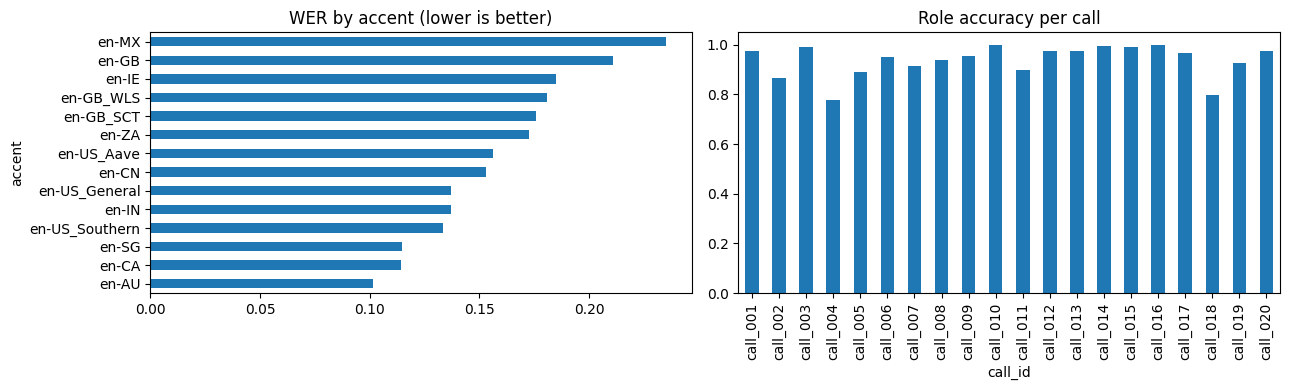

In [10]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ev.groupby("accent")["wer"].mean().sort_values().plot.barh(ax=ax[0], title="WER by accent (lower is better)")
ev.set_index("call_id")["role_accuracy"].plot.bar(ax=ax[1], title="Role accuracy per call", ylim=(0, 1.05))
plt.tight_layout(); plt.show()

## 5. Error analysis

**Results (20 calls):** Corpus WER **15.9%** (basic normalization) / **13.3%** (Whisper normalizer) · mean role accuracy **93.7%** · mean DER **18.7%**.

- **Roles:** Agent/Customer were assigned correctly in all 20 calls (lowest role accuracy 78%; a swap would score < 50%). The LLM reasoned from greetings and self-introductions (e.g., *"Speaker_01 greets, introduces themselves as a representative…"*, confidence 0.99).
- **Remaining role errors** come from diarization, not role labelling: short customer back-channels ("yeah", "oh") inside agent speech are absorbed into the agent's turn.
- **WER sources:**
  1. Formatting differences: the reference spells numbers as words while Whisper writes digits. The Whisper normalizer removes these, lowering WER from 15.9% to 13.3%.
  2. Proper nouns: "Fox Courier" → "Fox Korea", "Tullamarine" → "Tulamar and".
  3. Acoustic confusions: "hear that" → "hear dad".
  4. The human reference itself has small omissions, found during the manual listening check.
- **By accent:** British accents (en-GB, en-GB_SCT, en-GB_WLS) have the highest WER and lowest role accuracy; en-MX is highest but based on one call. With 1–2 calls per accent, accent differences are indicative only.
- **Unclear-audio flag:** few turns were flagged; some are false positives on very short words ("Okay.") where Whisper's confidence is naturally lower.